#Analise Pergunta norteadora
### De que forma a variação na demanda por categorias de produtos entre as diferentes macrorregiões impacta a composição da receita total, e como a distribuição geográfica dos sellers pode ser otimizada para atender às preferências locais e alavancar o ticket médio?



Lendo os 16 arquivos diretamente da pasta do Colab...
Unificando bases e limpando dados nulos essenciais...
Preparando e calculando variáveis analíticas...


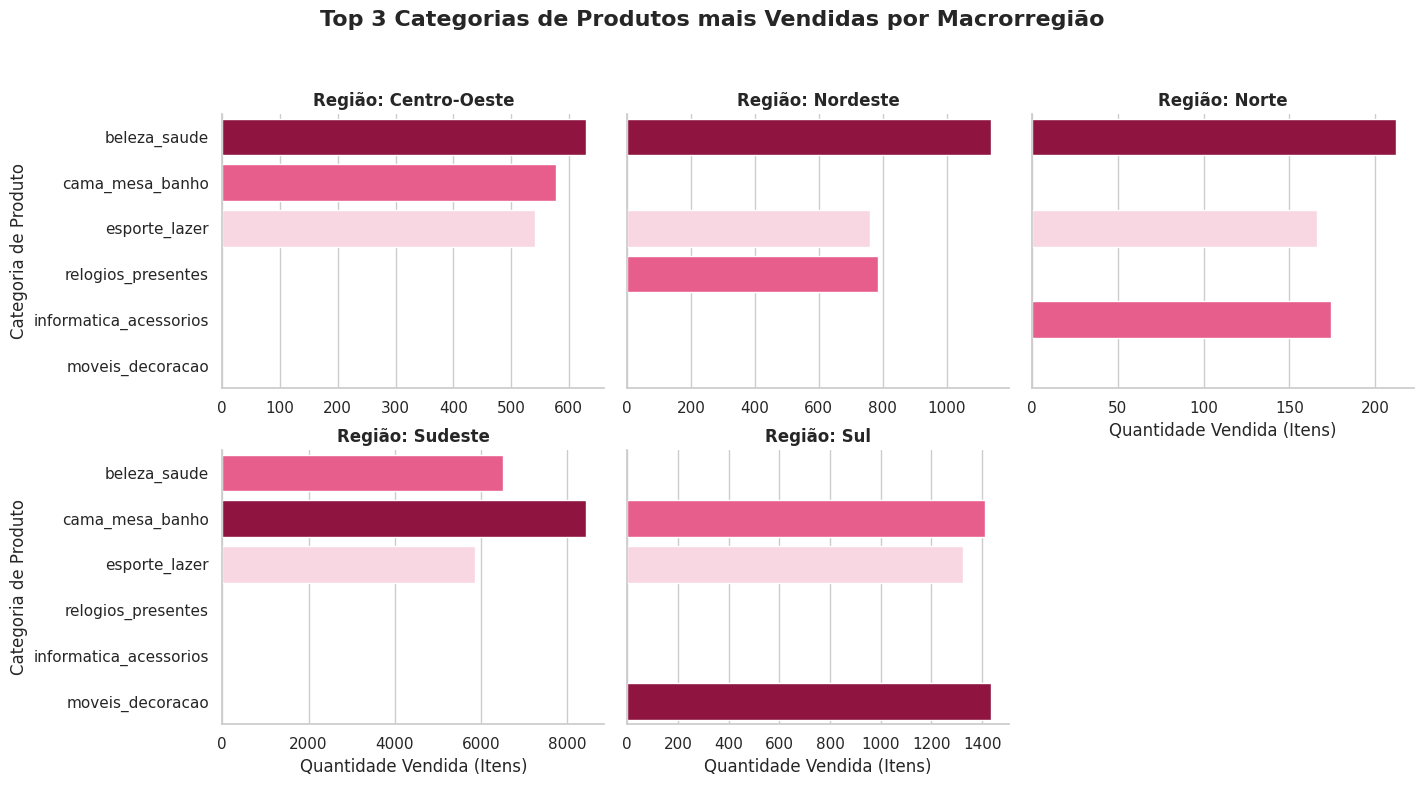

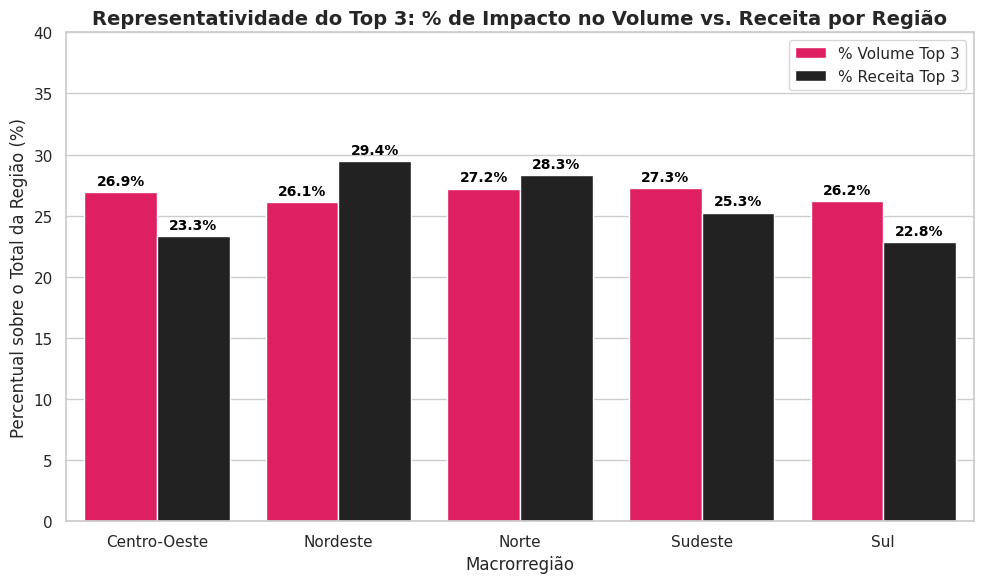

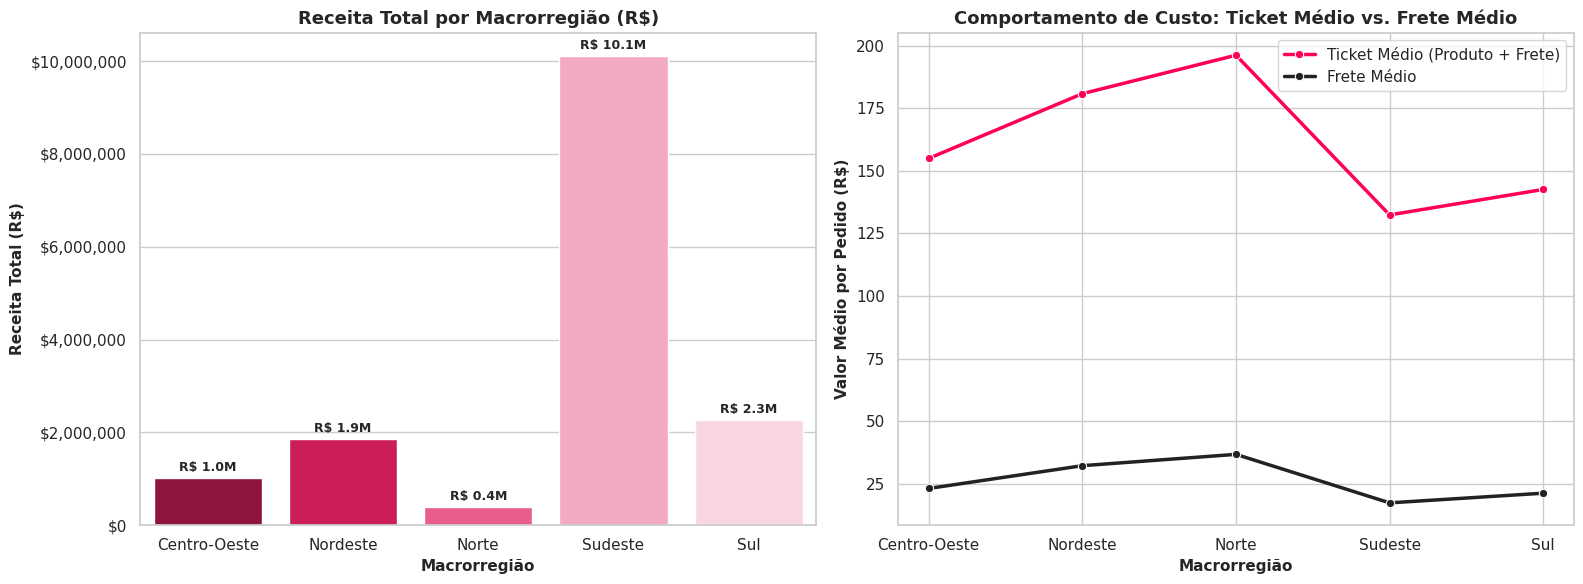

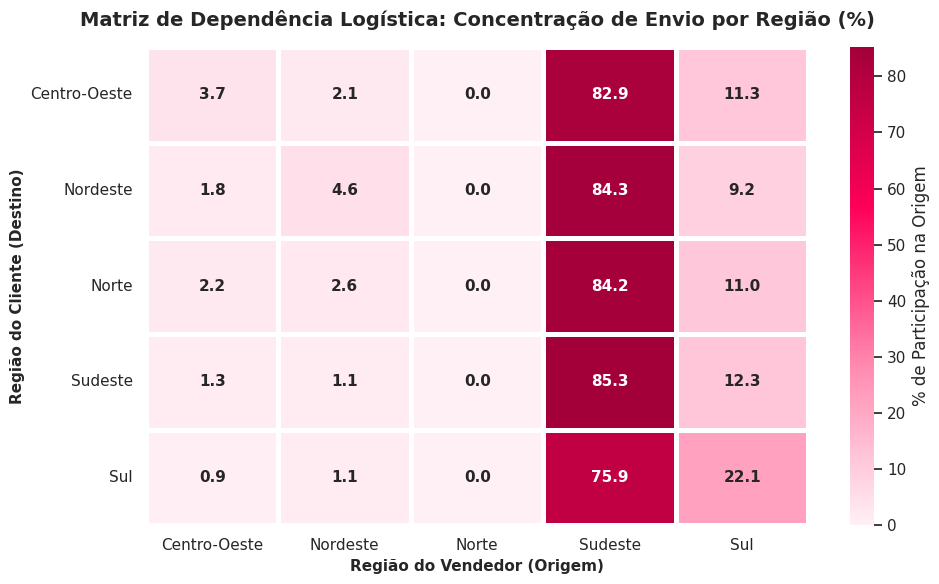

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Paleta de cores padrão do trabalho (identidade FIAP) ----
from cycler import cycler
ROSA = "#FE0058"           # cor principal / destaque
ROSA_ESCURO = "#A3003A"
ROSA_CLARO = "#FF8AB0"
GRAFITE = "#222222"        # cor secundária
CINZA = "#8C8C8C"
PALETA = [ROSA, GRAFITE, CINZA, ROSA_ESCURO, ROSA_CLARO]
plt.rcParams["axes.prop_cycle"] = cycler(color=PALETA)
from matplotlib.colors import LinearSegmentedColormap
CMAP_FIAP = LinearSegmentedColormap.from_list("fiap", [ROSA_ESCURO, ROSA, ROSA_CLARO, "#FFD1E0"])
CMAP_CALOR = LinearSegmentedColormap.from_list("fiap_calor", ["#FFF0F5", ROSA_CLARO, ROSA, ROSA_ESCURO])
def paleta_fiap(n):
    return [CMAP_FIAP(i / max(n - 1, 1)) for i in range(n)]

print("Lendo os 16 arquivos diretamente da pasta do Colab...")

# Compatibilidade de caminho de arquivo no Colab ou ambiente local
path_prefix = '/content/' if os.path.exists('/content/olist_orders_tratado.csv') else ''

# ==============================================================================
# 1. CARREGAMENTO DOS 16 ARQUIVOS DA BASE DE DADOS
# ==============================================================================
# Tabelas Principais Tratadas
orders_df = pd.read_csv(os.path.join(path_prefix, 'olist_orders_tratado.csv'))
customers_df = pd.read_csv(os.path.join(path_prefix, 'olist_customers_tratado.csv'))
order_items_df = pd.read_csv(os.path.join(path_prefix, 'olist_order_items_tratado.csv'))
products_df = pd.read_csv(os.path.join(path_prefix, 'olist_products_tratado.csv'))
sellers_df = pd.read_csv(os.path.join(path_prefix, 'olist_sellers_tratado.csv'))
payments_df = pd.read_csv(os.path.join(path_prefix, 'olist_order_payments_tratado.csv'))
reviews_df = pd.read_csv(os.path.join(path_prefix, 'olist_order_reviews_tratado.csv'))
geolocation_df = pd.read_csv(os.path.join(path_prefix, 'olist_geolocation_tratado.csv'))

# Tabelas Auxiliares e Dicionários
category_translation_df = pd.read_csv(os.path.join(path_prefix, 'product_category_name_translation_tratado.csv'))
quality_report_df = pd.read_csv(os.path.join(path_prefix, 'relatorio_qualidade_etl.csv'))
geo_unique_df = pd.read_csv(os.path.join(path_prefix, 'derivada_geolocation_consulta_unica.csv'))
data_dict_df = pd.read_csv(os.path.join(path_prefix, 'dicionario_dados_olist.csv'))

# Tabelas Integradas
integrated_items_products_sellers_df = pd.read_csv(os.path.join(path_prefix, 'integrada_items_products_sellers.csv'))
integrated_orders_customers_df = pd.read_csv(os.path.join(path_prefix, 'integrada_orders_customers.csv'))
integrated_payments_orders_df = pd.read_csv(os.path.join(path_prefix, 'integrada_payments_orders.csv'))
integrated_reviews_orders_df = pd.read_csv(os.path.join(path_prefix, 'integrada_reviews_orders.csv'))

# ==============================================================================
# 2. MAPEAMENTO DE REGIONALIZAÇÃO E UNIFICAÇÃO DA BASE
# ==============================================================================
def mapear_regiao(estado):
    sudeste = ['SP', 'RJ', 'MG', 'ES']
    sul = ['PR', 'SC', 'RS']
    nordeste = ['BA', 'PE', 'CE', 'MA', 'RN', 'PB', 'AL', 'SE', 'PI']
    centro_oeste = ['MT', 'MS', 'GO', 'DF']
    norte = ['AM', 'PA', 'AC', 'RO', 'RR', 'AP', 'TO']

    if estado in sudeste: return 'Sudeste'
    elif estado in sul: return 'Sul'
    elif estado in nordeste: return 'Nordeste'
    elif estado in centro_oeste: return 'Centro-Oeste'
    elif estado in norte: return 'Norte'
    else: return 'Outros'

print("Unificando bases e limpando dados nulos essenciais...")
df_ped_cli = pd.merge(orders_df, customers_df, on='id_cliente', how='inner')
df_base = pd.merge(order_items_df, df_ped_cli, on='id_pedido', how='inner')
df_base = pd.merge(df_base, products_df, on='id_produto', how='inner')
df_base = pd.merge(df_base, sellers_df, suffixes=('_cliente', '_vendedor'), on='id_vendedor', how='inner')

# Criando colunas essenciais e limpando nulos
df_base['regiao_cliente'] = df_base['estado_cliente'].apply(mapear_regiao)
df_base['regiao_vendedor'] = df_base['estado_vendedor'].apply(mapear_regiao)
df_base['receita_total_item'] = df_base['preco'] + df_base['valor_frete']
df_base['mesmo_estado'] = df_base['estado_vendedor'] == df_base['estado_cliente']

df_base = df_base.dropna(subset=['nome_categoria_produto', 'regiao_cliente'])

# ==============================================================================
# 3. CRIAÇÃO DAS TABELAS DE SUPORTE AOS GRÁFICOS
# ==============================================================================
print("Preparando e calculando variáveis analíticas...")

# 1. top3_tabela
grp_categorias = df_base.groupby(['regiao_cliente', 'nome_categoria_produto']).size().reset_index(name='Quantidade Vendida (Itens)')
grp_categorias = grp_categorias.sort_values(['regiao_cliente', 'Quantidade Vendida (Itens)'], ascending=[True, False])
top3_tabela = grp_categorias.groupby('regiao_cliente').head(3).copy()
top3_tabela.columns = ['Macrorregião', 'Categoria de Produto', 'Quantidade Vendida (Itens)']

# 2. tabela_impacto
volume_total_regiao = df_base.groupby('regiao_cliente').size().reset_index(name='Volume_Total')
receita_total_regiao = df_base.groupby('regiao_cliente')['receita_total_item'].sum().reset_index(name='Receita_Total')

volume_top3 = top3_tabela.groupby('Macrorregião')['Quantidade Vendida (Itens)'].sum().reset_index(name='Volume_Top3')
receita_top3 = df_base[df_base.apply(lambda row: (row['regiao_cliente'], row['nome_categoria_produto']) in zip(top3_tabela['Macrorregião'], top3_tabela['Categoria de Produto']), axis=1)].groupby('regiao_cliente')['receita_total_item'].sum().reset_index(name='Receita_Top3')

tabela_impacto = pd.merge(volume_total_regiao, receita_total_regiao, on='regiao_cliente')
tabela_impacto = pd.merge(tabela_impacto, volume_top3, left_on='regiao_cliente', right_on='Macrorregião')
tabela_impacto = pd.merge(tabela_impacto, receita_top3, on='regiao_cliente')

tabela_impacto['%_volume_top3'] = (tabela_impacto['Volume_Top3'] / tabela_impacto['Volume_Total']) * 100
tabela_impacto['%_receita_top3'] = (tabela_impacto['Receita_Top3'] / tabela_impacto['Receita_Total']) * 100

# 3. resumo_receita_regiao
resumo_receita_regiao = df_base.groupby('regiao_cliente').agg(
    receita_com_frete=('receita_total_item', 'sum'),
    ticket_medio_geral=('receita_total_item', 'mean'),
    frete_medio=('valor_frete', 'mean')
).reset_index()

total_brasil = pd.DataFrame([{
    'regiao_cliente': 'TOTAL BRASIL',
    'receita_com_frete': df_base['receita_total_item'].sum(),
    'ticket_medio_geral': df_base['receita_total_item'].mean(),
    'frete_medio': df_base['valor_frete'].mean()
}])
resumo_receita_regiao = pd.concat([resumo_receita_regiao, total_brasil], ignore_index=True)

# 4. cruzamento_logistico
cruzamento_logistico = pd.crosstab(
    index=df_base['regiao_cliente'],
    columns=df_base['regiao_vendedor'],
    normalize='index'
) * 100

# ==============================================================================
# GRÁFICO 1 - Gráfico de Barras Facetado
# ==============================================================================
sns.set_theme(style="whitegrid", palette=PALETA)
df_top3_plot = top3_tabela.reset_index() if 'Macrorregião' not in top3_tabela.columns else top3_tabela

g = sns.FacetGrid(df_top3_plot, col="Macrorregião", col_wrap=3, height=4, aspect=1.2, sharex=False)
g.map_dataframe(
    sns.barplot,
    x="Quantidade Vendida (Itens)",
    y="Categoria de Produto",
    hue="Categoria de Produto",
    palette=paleta_fiap(3),
    legend=False
)

g.set_titles(col_template="Região: {col_name}", size=12, weight='bold')
g.set_axis_labels("Quantidade Vendida (Itens)", "Categoria de Produto")
plt.subplots_adjust(top=0.85)
g.fig.suptitle("Top 3 Categorias de Produtos mais Vendidas por Macrorregião", fontsize=16, weight='bold')
plt.show()

# ==============================================================================
# GRÁFICO 2 - Gráfico de Barras Agrupadas
# ==============================================================================
df_plot_top3 = tabela_impacto[['regiao_cliente', '%_volume_top3', '%_receita_top3']].copy()
df_plot_top3.columns = ['Macrorregião', '% Volume Top 3', '% Receita Top 3']

df_melted = df_plot_top3.melt(
    id_vars='Macrorregião',
    value_vars=['% Volume Top 3', '% Receita Top 3'],
    var_name='Métrica',
    value_name='Percentual (%)'
)

plt.figure(figsize=(10, 6))
cores_personalizadas = [ROSA, GRAFITE]
ax = sns.barplot(data=df_melted, x='Macrorregião', y='Percentual (%)', hue='Métrica', palette=cores_personalizadas)

plt.title('Representatividade do Top 3: % de Impacto no Volume vs. Receita por Região', fontsize=14, fontweight='bold')
plt.xlabel('Macrorregião', fontsize=12)
plt.ylabel('Percentual sobre o Total da Região (%)', fontsize=12)
plt.ylim(0, 40)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, color='black', weight='bold', xytext=(0, 3),
                    textcoords='offset points')

plt.legend(title='', loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICO 3 - Painel Duplo de Gráficos Combinados
# ==============================================================================
df_regioes_grafico = resumo_receita_regiao[resumo_receita_regiao['regiao_cliente'] != 'TOTAL BRASIL'].copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=df_regioes_grafico,
    x='regiao_cliente',
    y='receita_com_frete',
    ax=ax1,
    palette=paleta_fiap(5),
    hue='regiao_cliente',
    legend=False
)
ax1.set_title('Receita Total por Macrorregião (R$)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Macrorregião', fontsize=11, fontweight='bold')
ax1.set_ylabel('Receita Total (R$)', fontsize=11, fontweight='bold')
ax1.yaxis.set_major_formatter('${x:,.0f}')
ax1.tick_params(axis='x', rotation=0)

for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(f'R$ {height*1e-6:.1f}M',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

df_melted_ticket = df_regioes_grafico.melt(
    id_vars='regiao_cliente',
    value_vars=['ticket_medio_geral', 'frete_medio'],
    var_name='Métrica',
    value_name='Valor (R$)'
)
df_melted_ticket['Métrica'] = df_melted_ticket['Métrica'].replace({
    'ticket_medio_geral': 'Ticket Médio (Produto + Frete)',
    'frete_medio': 'Frete Médio'
})

sns.lineplot(
    data=df_melted_ticket,
    x='regiao_cliente',
    y='Valor (R$)',
    hue='Métrica',
    marker='o',
    linewidth=2.5,
    ax=ax2,
    palette=[ROSA, GRAFITE]
)

ax2.set_title('Comportamento de Custo: Ticket Médio vs. Frete Médio', fontsize=13, fontweight='bold')
ax2.set_xlabel('Macrorregião', fontsize=11, fontweight='bold')
ax2.set_ylabel('Valor Médio por Pedido (R$)', fontsize=11, fontweight='bold')
ax2.legend(title='', loc='upper right', frameon=True)
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICO 4 - Mapa de Calor (Heatmap) Matricial
# ==============================================================================
sns.set_theme(style="white", palette=PALETA)
plt.figure(figsize=(10, 6))

sns.heatmap(
    cruzamento_logistico,
    annot=True,
    fmt='.1f',
    cmap=CMAP_CALOR,
    cbar=True,
    linewidths=2.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    cbar_kws={'label': '% de Participação na Origem'}
)

plt.title('Matriz de Dependência Logística: Concentração de Envio por Região (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Região do Vendedor (Origem)', fontsize=11, fontweight='bold')
plt.ylabel('Região do Cliente (Destino)', fontsize=11, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()
